In [1]:
lugares = {
    "Plaza de Armas": (-13.5170, -71.9785),
    "Sacsayhuaman": (-13.5075, -71.9817),
    "Qorikancha": (-13.5195, -71.9761),
    "Mercado San Pedro": (-13.5202, -71.9819),
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

Plaza de Armas: lat=-13.517, lon=-71.9785
Sacsayhuaman: lat=-13.5075, lon=-71.9817
Qorikancha: lat=-13.5195, lon=-71.9761
Mercado San Pedro: lat=-13.5202, lon=-71.9819


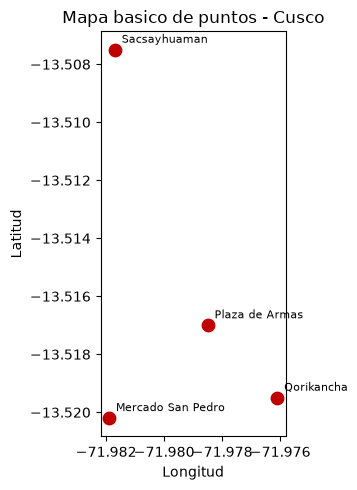

In [2]:
import matplotlib.pyplot as plt

lats = [v[0] for v in lugares.values()]
lons = [v[1] for v in lugares.values()]
nombres = list(lugares.keys())

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(lons, lats, c="#C00000", s=80)

for nombre, lon, lat in zip(nombres, lons, lats):
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Mapa basico de puntos - Cusco")
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("mapa_basico.png")

In [4]:
import math

def distancia_haversine(lat1, lon1, lat2, lon2):
    """Distancia en km entre dos coordenadas geograficas (formula de Haversine)."""
    R = 6371.0  # radio promedio de la Tierra en km
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi/2)**2 + math.cos(phi1)*math.cos(phi2)*math.sin(dlambda/2)**2
    c = 2*math.atan2(math.sqrt(a), math.sqrt(1-a))
    return R*c

In [5]:
lat0, lon0 = lugares["Plaza de Armas"]

for nombre, (lat, lon) in lugares.items():
    if nombre == "Plaza de Armas":
        continue
    d = distancia_haversine(lat0, lon0, lat, lon)
    print(f"Plaza de Armas -> {nombre}: {d:.4f} km")

Plaza de Armas -> Sacsayhuaman: 1.1116 km
Plaza de Armas -> Qorikancha: 0.3803 km
Plaza de Armas -> Mercado San Pedro: 0.5116 km


In [6]:
import json

features = []
for nombre, (lat, lon) in lugares.items():
    features.append({
        "type": "Feature",
        "properties": {"nombre": nombre},
        "geometry": {"type": "Point", "coordinates": [lon, lat]}  # OJO: orden lon, lat
    })

geojson_cusco = {"type": "FeatureCollection", "features": features}

with open("lugares_cusco.geojson", "w") as f:
    json.dump(geojson_cusco, f, indent=2)

print("Archivo guardado con", len(features), "features")

Archivo guardado con 4 features


In [7]:
with open("lugares_cusco.geojson") as f:
    data = json.load(f)

print("Cantidad de features:", len(data["features"]))
print("Primer lugar:", data["features"][0]["properties"]["nombre"])
print("Sus coordenadas [lon, lat]:", data["features"][0]["geometry"]["coordinates"])

Cantidad de features: 4
Primer lugar: Plaza de Armas
Sus coordenadas [lon, lat]: [-71.9785, -13.517]


In [8]:
mis_lugares = {
    "Cristo Blanco": (-13.5097, -71.9781),
    "Qenqo": (-13.5106, -71.9717),
    "Plazoleta de San Blas": (-13.5152, -71.9743),
}

for nombre, (lat, lon) in mis_lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

Cristo Blanco: lat=-13.5097, lon=-71.9781
Qenqo: lat=-13.5106, lon=-71.9717
Plazoleta de San Blas: lat=-13.5152, lon=-71.9743


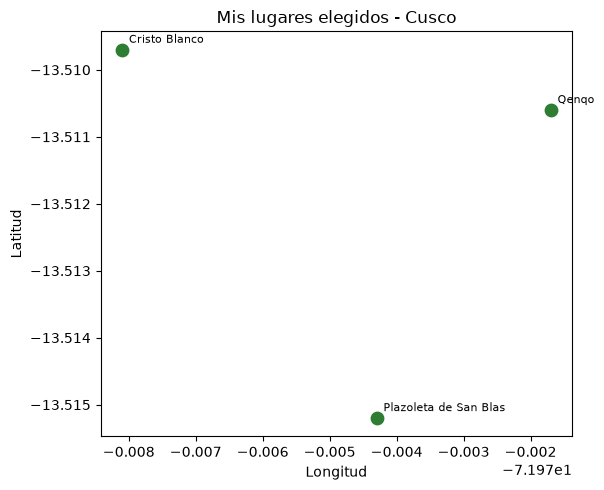

In [9]:
import matplotlib.pyplot as plt

lats = [v[0] for v in mis_lugares.values()]
lons = [v[1] for v in mis_lugares.values()]
nombres = list(mis_lugares.keys())

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(lons, lats, c="#2E7D32", s=80)

for nombre, lon, lat in zip(nombres, lons, lats):
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Mis lugares elegidos - Cusco")
ax.set_aspect("equal")
plt.tight_layout()
plt.savefig("mis_lugares_mapa.png")

In [10]:
lat0, lon0 = mis_lugares["Cristo Blanco"]

for nombre, (lat, lon) in mis_lugares.items():
    if nombre == "Cristo Blanco":
        continue
    d = distancia_haversine(lat0, lon0, lat, lon)
    print(f"Cristo Blanco -> {nombre}: {d:.4f} km")

Cristo Blanco -> Qenqo: 0.6992 km
Cristo Blanco -> Plazoleta de San Blas: 0.7368 km


In [11]:
import json

mis_features = []
for nombre, (lat, lon) in mis_lugares.items():
    mis_features.append({
        "type": "Feature",
        "properties": {"nombre": nombre},
        "geometry": {"type": "Point", "coordinates": [lon, lat]}  # OJO: orden lon, lat
    })

mi_geojson = {"type": "FeatureCollection", "features": mis_features}

with open("mis_lugares.geojson", "w") as f:
    json.dump(mi_geojson, f, indent=2)

print("Archivo guardado con", len(mis_features), "features")

Archivo guardado con 3 features


In [12]:
with open("mis_lugares.geojson") as f:
    data = json.load(f)

print("Cantidad de features:", len(data["features"]))
print("Primer lugar:", data["features"][0]["properties"]["nombre"])
print("Sus coordenadas [lon, lat]:", data["features"][0]["geometry"]["coordinates"])

Cantidad de features: 3
Primer lugar: Cristo Blanco
Sus coordenadas [lon, lat]: [-71.9781, -13.5097]
